# 02 — PAC Learning & VC Dimension
### From Finite Hypothesis Classes to Shattering

---

> **Position in the series:**
> `01_statistical_learning_theory` → **`02_pac_and_vc_dimensions`** → `03_linear_algebra_and_geometry` → `04_pca` → `05_gaussian_mixture_models` → `06_linear_regression` → `07_logistic_regression` → `08_svm_and_kernel_methods`

**Goal:** Make the notion of "learning that generalizes" mathematically precise. We define when a hypothesis class is learnable, how many samples are needed, and how to measure the complexity of a hypothesis class — both for finite and infinite cases.

## References

| # | Source |
|---|--------|
| [1] | S. Shalev-Shwartz & S. Ben-David — *Understanding Machine Learning: From Theory to Algorithms*, Cambridge University Press, 2014 — Ch. 2–6 (PAC, agnostic PAC, uniform convergence, VC dimension, Fundamental Theorem) |
| [2] | M. Mohri, A. Rostamizadeh & A. Talwalkar — *Foundations of Machine Learning*, 2nd ed., MIT Press, 2018 — Ch. 2 (PAC framework, axis-aligned rectangles), Ch. 3 (VC dimension) |
| [3] | M. J. Kearns & U. V. Vazirani — *An Introduction to Computational Learning Theory*, MIT Press, 1994 — Ch. 1 (efficient PAC learning), Ch. 3 (VC dimension) |
| [4] | V. N. Vapnik — *The Nature of Statistical Learning Theory*, Springer, 1995 |
| [5] | L. G. Valiant — *A Theory of the Learnable*, Communications of the ACM, 27(11), 1984 |
| [6] | Lecture notes, SMIA Sapienza |

---

## Structure
1. PAC Learning — Consistent Learner (Realizable Case): definition, sample complexity, finite classes, the rectangle learner and a Monte Carlo check of its bound
2. Agnostic PAC Learning: Hoeffding's inequality, uniform convergence, consistent vs agnostic sample complexity
3. VC Dimension: shattering, linear classifiers, from VC dimension to a bound (growth function, Sauer–Shelah, Fundamental Theorem)
4. Summary

---
# 1. PAC Learning — Consistent Learner (Realizable Case)

## 1.1 Setup and Motivation

In Section 1 we saw that ERM can overfit. The natural question is:

> *Under what precise conditions does ERM produce a hypothesis that generalizes? And how much data do we need?*

**PAC Learning** (Probably Approximately Correct — Valiant, 1984) gives a rigorous answer.

We work under the **realizable assumption**: there exists a true concept $c^* \in \mathcal{H}$ such that $y_i = c^*(x_i)$ for all training points — zero training error is achievable.

---

## 1.2 Formal Definition — PAC Learnability

**Definition (PAC Learnability):** A hypothesis class $\mathcal{H}$ is **PAC learnable** if there exists an algorithm $A$ and a function $m(\epsilon, \delta): (0,1)^2 \to \mathbb{N}$ such that for every $\epsilon, \delta \in (0,1)$, for every distribution $\mathcal{D}$ over $\mathcal{X}$, and for every target concept $c^* \in \mathcal{H}$:

$$
\forall\, m \geq m(\epsilon, \delta), \quad P_{S \sim \mathcal{D}^m}\left[R(h_S) \leq \epsilon\right] \geq 1 - \delta
$$

Reading the formula carefully:
- $\epsilon$ — **accuracy**: how close to optimal we want to be (small = more accurate)
- $\delta$ — **confidence**: probability of failure we can tolerate (small = more confident)
- $m(\epsilon, \delta)$ — **sample complexity**: the minimum number of samples needed
- The bound must hold for **any** distribution and **any** target in $\mathcal{H}$

The name says it all: with $m \geq m(\epsilon, \delta)$ samples, our learner is **probably** ($1-\delta$) **approximately correct** ($R \leq \epsilon$).

---

## 1.3 Sample Complexity — Definition

The **sample complexity** $m(\epsilon, \delta)$ is the minimum number of i.i.d. training examples sufficient to guarantee PAC learnability:

$$
\boxed{m(\epsilon, \delta) = \min\left\{ m \in \mathbb{N} \;:\; \forall\, \mathcal{D},\, c^* \in \mathcal{H},\; P\left[R(h_S) \leq \epsilon\right] \geq 1-\delta \right\}}
$$

Intuitively: $m(\epsilon, \delta)$ answers the question *"how much data is enough?"* as a function of how accurate and how confident we want to be.

A hypothesis class is **efficiently PAC learnable** if it is PAC learnable by an algorithm $A$ whose **running time** is polynomial in $1/\epsilon$, $1/\delta$ and the size of the problem (the dimension of $x$ and the size of the representation of $c^*$) (Valiant, 1984; Kearns & Vazirani, Ch. 1). Since an algorithm must at least read its input, this forces the sample complexity to be polynomial as well — but the converse fails: a class can have polynomial sample complexity (e.g. any finite class, §1.4) and still be computationally hard to learn, because finding a consistent hypothesis can be NP-hard.

## 1.4 Proof — Finite Hypothesis Class, Consistent Learner

**Theorem:** Let $\mathcal{H}$ be a finite hypothesis class and let $A$ be any consistent learner (i.e., $\hat{R}_S(h_S) = 0$). Then for any $\epsilon, \delta \in (0,1)$:

$$
P\left[R(h_S) > \epsilon\right] \leq |\mathcal{H}|\, e^{-\epsilon m}
$$

Setting this $\leq \delta$ and solving for $m$ gives:

$$
\boxed{m \geq \frac{1}{\epsilon}\left(\log|\mathcal{H}| + \log\frac{1}{\delta}\right)}
$$

---

### Proof sketch

**Step 1 — Define a bad hypothesis.**
Call $h \in \mathcal{H}$ **bad** if its true risk exceeds $\epsilon$:
$$h \text{ is bad} \iff R(h) > \epsilon$$
We want to show that $A$ is unlikely to output a bad hypothesis.

**Step 2 — Probability that a bad $h$ is consistent with $S$.**
Fix any hypothesis $h$ with $R(h) > \epsilon$ ($h$ is fixed before the sample is drawn; only $S$ is random). Each training point $(x_i, y_i)$ is correctly classified by $h$ with probability at most $1 - \epsilon$ (since $h$ makes an error on at least a fraction $\epsilon$ of the distribution), and the $m$ points are i.i.d. Therefore, for every fixed $h$ with $R(h) > \epsilon$:
$$P_{S \sim \mathcal{D}^m}\left[\hat{R}_S(h) = 0\right] \leq (1-\epsilon)^m \leq e^{-\epsilon m}$$

**Step 3 — Union bound over all bad hypotheses.**
There are at most $|\mathcal{H}|$ bad hypotheses. By the union bound:
$$P\left[\exists\, h \in \mathcal{H} : R(h) > \epsilon \text{ and } \hat{R}_S(h) = 0\right] \leq |\mathcal{H}|\, e^{-\epsilon m}$$

Since $A$ is consistent (it returns an $h$ with $\hat{R}_S = 0$), any bad $h$ it could return is covered by this bound.

**Step 4 — Solve for $m$.**
Set $|\mathcal{H}|\, e^{-\epsilon m} \leq \delta$:
$$e^{-\epsilon m} \leq \frac{\delta}{|\mathcal{H}|} \implies -\epsilon m \leq \log\frac{\delta}{|\mathcal{H}|} \implies m \geq \frac{1}{\epsilon}\log\frac{|\mathcal{H}|}{\delta}$$

which can be written as:
$$m \geq \frac{1}{\epsilon}\left(\log|\mathcal{H}| + \log\frac{1}{\delta}\right) \qquad \square$$

**Key observation:** The sample complexity grows **logarithmically** in $|\mathcal{H}|$ — even if we double the hypothesis class, we only need an additive $\frac{\log 2}{\epsilon}$ extra samples.

## 1.5 The Rectangle Learner — A Concrete Realization

The rectangle learner is one of the most elegant concrete examples of PAC learning. It makes the abstract machinery completely visual.

### Setup

- **Input space:** $\mathcal{X} = \mathbb{R}^2$
- **Output space:** $\mathcal{Y} = \{0, 1\}$ (positive / negative)
- **Hypothesis class:** $\mathcal{H} = $ all axis-aligned rectangles in $\mathbb{R}^2$
- **Target concept:** $c^* \in \mathcal{H}$ — the true (unknown) rectangle that labels points as positive

A point $x \in \mathbb{R}^2$ is labeled $+1$ if it falls inside $c^*$, and $-1$ otherwise.

### The Tightest Fit Algorithm

The consistent learner for this class is the **tightest fit** (smallest enclosing rectangle):

$$h_S = \text{smallest rectangle containing all positive training points}$$

This is the key idea: we want a generic hypothesis $h \in \mathcal{H}$ to **coincide** as closely as possible with the concept space $c^*$. The tightest fit is our best approximation of $c^*$ from the observed positive points — it is always a subset of $c^*$ (consistent, since it makes no false positives on the training set).

### Probabilistic Analysis — The Four-Strip Argument

Because $h_S \subseteq c^*$, the learner never produces false positives, and its true risk is the probability mass of the region of $c^*$ it misses:
$$R(h_S) = P_{x \sim \mathcal{D}}[x \in c^* \setminus h_S]$$

Fix $\epsilon$. If $P_{\mathcal D}(c^*) \leq \epsilon$ there is nothing to prove, since $R(h_S) \leq P_{\mathcal D}(c^*) \leq \epsilon$. Otherwise, define four strips $E_N, E_S, E_E, E_W$ **inside** $c^*$, each running along one side of $c^*$ (North, South, East, West) and each with probability mass exactly $\epsilon/4$:
$$P_{\mathcal D}(E_N) = P_{\mathcal D}(E_S) = P_{\mathcal D}(E_E) = P_{\mathcal D}(E_W) = \frac{\epsilon}{4}$$

Strips with mass *exactly* $\epsilon/4$ exist when $\mathcal D$ is **continuous** (has a density), because then the mass of a strip varies continuously with its width. For a general $\mathcal D$ one takes the thinnest strip with mass $\geq \epsilon/4$, and the argument goes through with minor changes (Mohri et al., §2.1).

**Geometric fact.** Suppose the training sample $S$ contains at least one point in every strip. A training point in $E_i \subseteq c^*$ is a positive example, so the tightest fit must contain it: the corresponding side of $h_S$ then lies inside $E_i$, and the part of $c^*$ beyond that side is contained in $E_i$. Hence $c^* \setminus h_S \subseteq E_N \cup E_S \cup E_E \cup E_W$ and $R(h_S) \leq 4 \cdot \frac{\epsilon}{4} = \epsilon$. Taking the contrapositive, the **bad event** is that some strip receives no training point:
$$R(h_S) > \epsilon \;\implies\; \exists\, i \in \{N,S,E,W\} : \; S \cap E_i = \emptyset$$

**Union bound.** Since the $m$ points are i.i.d. and each one falls outside $E_i$ with probability $1 - \epsilon/4$:
$$
\begin{aligned}
P\big(R(h_S) > \epsilon\big) &\le P\Big(\bigcup_{i \in \{N,S,E,W\}} \{S \cap E_i = \emptyset\}\Big)
\le \sum_{i \in \{N,S,E,W\}} P\big(S \cap E_i = \emptyset\big) \\
&= 4\left(1 - \frac{\epsilon}{4}\right)^m \le 4e^{-m\epsilon/4}
\end{aligned}
$$
using $1 - x \le e^{-x}$. Setting the right-hand side $\le \delta$:
$$\boxed{m \ge \frac{4}{\epsilon} \ln\frac{4}{\delta}}$$

This is polynomial in $1/\epsilon$ and $1/\delta$, and the tightest fit runs in $O(m)$ time (four min/max operations), so axis-aligned rectangles are **efficiently** PAC learnable in the sense of §1.3.

The demo below draws $m = 30$ points from the uniform distribution on $[0,1]^2$. The right panel shows the error region $c^* \setminus h_S$ together with the four strips $E_i$ for $\epsilon = 0.2$.

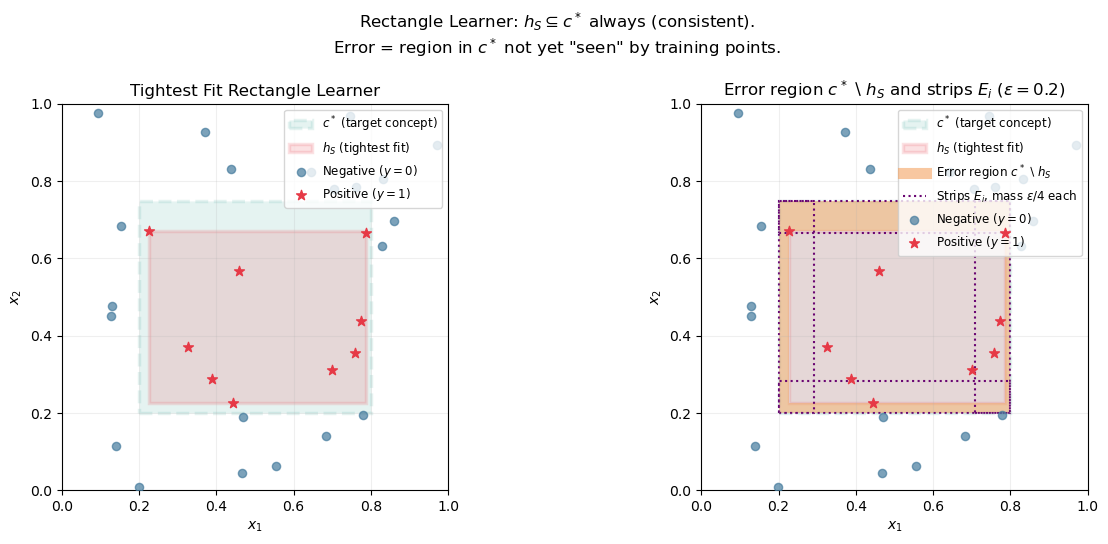

R(h_S) = area(c*) - area(h_S) = 0.0822   (eps = 0.2)
  strip E_N: contains 1 training point(s)
  strip E_S: contains 1 training point(s)
  strip E_E: contains 3 training point(s)
  strip E_W: contains 1 training point(s)

=== Rectangle Learner — Sample Complexity ===
  ε=0.10, δ=0.10  →  m ≥ 148 samples
  ε=0.10, δ=0.05  →  m ≥ 176 samples
  ε=0.05, δ=0.10  →  m ≥ 296 samples
  ε=0.05, δ=0.05  →  m ≥ 351 samples
  ε=0.01, δ=0.10  →  m ≥ 1476 samples
  ε=0.01, δ=0.05  →  m ≥ 1753 samples


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

rng = np.random.default_rng(42)

# --- Target concept c* (uniform D on [0,1]^2) ---
c_star = dict(x0=0.2, y0=0.2, x1=0.8, y1=0.75)
area_c = (c_star['x1'] - c_star['x0']) * (c_star['y1'] - c_star['y0'])

def inside(pts, rect):
    return ((pts[:,0] >= rect['x0']) & (pts[:,0] <= rect['x1']) &
            (pts[:,1] >= rect['y0']) & (pts[:,1] <= rect['y1']))

# Generate training points
n_train = 30
X = rng.uniform(0, 1, (n_train, 2))
y = inside(X, c_star).astype(int)

pos = X[y == 1]
neg = X[y == 0]

# Tightest fit: smallest enclosing rectangle around positive points
h_S = dict(
    x0=pos[:,0].min(), y0=pos[:,1].min(),
    x1=pos[:,0].max(), y1=pos[:,1].max()
)

# Strips E_i of mass eps/4 inside c* (uniform D: mass = area)
eps_demo = 0.2
w_c, h_c = c_star['x1'] - c_star['x0'], c_star['y1'] - c_star['y0']
t_ns = (eps_demo / 4) / w_c        # thickness of North/South strips
t_ew = (eps_demo / 4) / h_c        # thickness of East/West strips
E = {
    'N': dict(x0=c_star['x0'], y0=c_star['y1'] - t_ns, x1=c_star['x1'], y1=c_star['y1']),
    'S': dict(x0=c_star['x0'], y0=c_star['y0'],        x1=c_star['x1'], y1=c_star['y0'] + t_ns),
    'E': dict(x0=c_star['x1'] - t_ew, y0=c_star['y0'], x1=c_star['x1'], y1=c_star['y1']),
    'W': dict(x0=c_star['x0'], y0=c_star['y0'],        x1=c_star['x0'] + t_ew, y1=c_star['y1']),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, title, show_strips in zip(
    axes,
    ['Tightest Fit Rectangle Learner', f'Error region $c^* \\setminus h_S$ and strips $E_i$ ($\\epsilon={eps_demo}$)'],
    [False, True]
):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.2)

    # Target concept c*
    rect_cstar = patches.Rectangle(
        (c_star['x0'], c_star['y0']), w_c, h_c,
        linewidth=2.5, edgecolor='#2A9D8F', facecolor='#2A9D8F', alpha=0.12,
        linestyle='--', label='$c^*$ (target concept)'
    )
    ax.add_patch(rect_cstar)

    # Tightest fit h_S
    rect_hS = patches.Rectangle(
        (h_S['x0'], h_S['y0']),
        h_S['x1'] - h_S['x0'],
        h_S['y1'] - h_S['y0'],
        linewidth=2.5, edgecolor='#E63946', facecolor='#E63946', alpha=0.15,
        label='$h_S$ (tightest fit)'
    )
    ax.add_patch(rect_hS)

    if show_strips:
        # Error region c* \ h_S, drawn as four pieces
        err = [
            (c_star['x0'], c_star['y0'], w_c, h_S['y0'] - c_star['y0']),
            (c_star['x0'], h_S['y1'],    w_c, c_star['y1'] - h_S['y1']),
            (c_star['x0'], h_S['y0'],    h_S['x0'] - c_star['x0'], h_S['y1'] - h_S['y0']),
            (h_S['x1'],    h_S['y0'],    c_star['x1'] - h_S['x1'], h_S['y1'] - h_S['y0']),
        ]
        for (sx, sy, sw, sh) in err:
            if sw > 0 and sh > 0:
                ax.add_patch(patches.Rectangle((sx, sy), sw, sh,
                    facecolor='#F4A261', alpha=0.55, edgecolor='#F4A261', linewidth=0))
        ax.plot([], [], color='#F4A261', linewidth=8, alpha=0.6, label='Error region $c^* \\setminus h_S$')
        # Strips E_i of mass eps/4
        for r in E.values():
            ax.add_patch(patches.Rectangle((r['x0'], r['y0']), r['x1'] - r['x0'], r['y1'] - r['y0'],
                fill=False, edgecolor='#6A0572', linestyle=':', linewidth=1.5))
        ax.plot([], [], color='#6A0572', linestyle=':', label='Strips $E_i$, mass $\\epsilon/4$ each')

    # Data points
    ax.scatter(neg[:,0], neg[:,1], c='#457B9D', s=35, zorder=5, label='Negative ($y=0$)', alpha=0.7)
    ax.scatter(pos[:,0], pos[:,1], c='#E63946', s=55, marker='*', zorder=6, label='Positive ($y=1$)')

    ax.set_title(title, fontsize=12)
    ax.legend(fontsize=8.5, loc='upper right')
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

plt.suptitle(
    'Rectangle Learner: $h_S \\subseteq c^*$ always (consistent).\n'
    'Error = region in $c^*$ not yet "seen" by training points.',
    fontsize=12
)
plt.tight_layout()
plt.show()

# Exact risk under the uniform distribution, and the bad events S ∩ E_i = ∅
risk_demo = area_c - (h_S['x1'] - h_S['x0']) * (h_S['y1'] - h_S['y0'])
print(f"R(h_S) = area(c*) - area(h_S) = {risk_demo:.4f}   (eps = {eps_demo})")
for k, r in E.items():
    print(f"  strip E_{k}: contains {inside(X, r).sum()} training point(s)")

# Sample complexity for rectangle learner
print("\n=== Rectangle Learner — Sample Complexity ===")
for eps in [0.1, 0.05, 0.01]:
    for delta in [0.1, 0.05]:
        m = int(np.ceil((4 / eps) * np.log(4 / delta)))
        print(f"  ε={eps:.2f}, δ={delta:.2f}  →  m ≥ {m} samples")

## 1.6 Monte Carlo Check of the Bound $P[R(h_S) > \epsilon] \le 4e^{-m\epsilon/4}$

A single training sample cannot verify a statement about a *probability* over samples: on one draw, $R(h_S) \le \epsilon$ either happens or it does not. To check the bound we repeat the whole experiment many times.

For each sample size $m$ we draw $10{,}000$ independent training sets $S \sim \mathcal D^m$ (with $\mathcal D$ uniform on $[0,1]^2$ and the same $c^*$ as above), run the tightest-fit learner on each, and compute its true risk **exactly**: under the uniform distribution $R(h_S) = \text{area}(c^*) - \text{area}(h_S)$ (with $h_S = \emptyset$ when $S$ has no positive point). The fraction of runs with $R(h_S) > \epsilon$ estimates $P_{S\sim\mathcal D^m}[R(h_S) > \epsilon]$, which we compare with the bound on a log scale.

As the plot below shows, the bound holds at every $m$ but is conservative: the estimated failure probability is about $5\times$ smaller at $m = 50$ and more than two orders of magnitude smaller for $m \geq 150$. The slack comes from the union bound over the four strips and, above all, from the fact that the bound holds for **every** continuous $\mathcal D$ and every $c^*$, not just for this one.

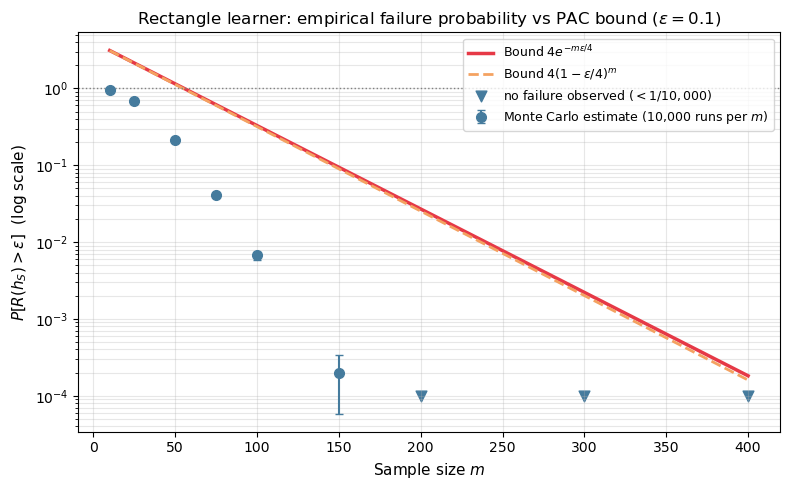

    m |  P_hat[R>eps] |   ± s.e. |  4(1-eps/4)^m | 4exp(-m eps/4)
------------------------------------------------------------------
   10 |        0.9675 |   0.0018 |        3.1053 |         3.1152
   25 |        0.6850 |   0.0046 |        2.1241 |         2.1410
   50 |        0.2105 |   0.0041 |        1.1280 |         1.1460
   75 |        0.0405 |   0.0020 |        0.5990 |         0.6134
  100 |        0.0067 |   0.0008 |        0.3181 |         0.3283
  150 |        0.0002 |   0.0001 |        0.0897 |         0.0941
  200 |        0.0000 |   0.0000 |        0.0253 |         0.0270
  300 |        0.0000 |   0.0000 |        0.0020 |         0.0022
  400 |        0.0000 |   0.0000 |        0.0002 |         0.0002

Bound respected at every m: True


In [2]:
# Monte Carlo estimate of P[R(h_S) > eps] for the tightest-fit learner
rng = np.random.default_rng(0)
eps = 0.1
n_trials = 10_000
ms = np.array([10, 25, 50, 75, 100, 150, 200, 300, 400])

def rectangle_risks(m, n_trials, rng):
    # True risks R(h_S) of n_trials independent runs with m points each (exact areas)
    X = rng.uniform(0, 1, (n_trials, m, 2))
    is_pos = ((X[..., 0] >= c_star['x0']) & (X[..., 0] <= c_star['x1']) &
              (X[..., 1] >= c_star['y0']) & (X[..., 1] <= c_star['y1']))
    lo = np.where(is_pos[..., None], X,  np.inf).min(axis=1)   # (n_trials, 2)
    hi = np.where(is_pos[..., None], X, -np.inf).max(axis=1)
    sides = np.clip(hi - lo, 0, None)                           # 0 if no positive point
    return area_c - sides[:, 0] * sides[:, 1]

p_hat = np.array([np.mean(rectangle_risks(m, n_trials, rng) > eps) for m in ms])
se = np.sqrt(p_hat * (1 - p_hat) / n_trials)
bound_exact = 4 * (1 - eps / 4) ** ms
bound_exp = 4 * np.exp(-ms * eps / 4)

fig, ax = plt.subplots(figsize=(8, 5))
m_grid = np.linspace(ms.min(), ms.max(), 300)
ax.semilogy(m_grid, 4 * np.exp(-m_grid * eps / 4), '#E63946', lw=2.5, label='Bound $4e^{-m\\epsilon/4}$')
ax.semilogy(m_grid, 4 * (1 - eps / 4) ** m_grid, '#F4A261', lw=2, linestyle='--', label='Bound $4(1-\\epsilon/4)^m$')
nz = p_hat > 0
ax.errorbar(ms[nz], p_hat[nz], yerr=se[nz], fmt='o', color='#457B9D', ms=7, capsize=3,
            label=f'Monte Carlo estimate ({n_trials:,} runs per $m$)')
if (~nz).any():
    ax.scatter(ms[~nz], np.full((~nz).sum(), 1 / n_trials), marker='v', color='#457B9D', s=60,
               label=f'no failure observed ($< 1/{n_trials:,}$)')
ax.axhline(1, color='gray', lw=1, linestyle=':')
ax.set_xlabel('Sample size $m$', fontsize=11)
ax.set_ylabel('$P[R(h_S) > \\epsilon]$  (log scale)', fontsize=11)
ax.set_title(f'Rectangle learner: empirical failure probability vs PAC bound ($\\epsilon={eps}$)', fontsize=12)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

print(f"{'m':>5} | {'P_hat[R>eps]':>13} | {'± s.e.':>8} | {'4(1-eps/4)^m':>13} | {'4exp(-m eps/4)':>14}")
print("-" * 66)
for m, p, s, b1, b2 in zip(ms, p_hat, se, bound_exact, bound_exp):
    print(f"{m:>5} | {p:>13.4f} | {s:>8.4f} | {b1:>13.4f} | {b2:>14.4f}")
print("\nBound respected at every m:", bool(np.all(p_hat <= bound_exact)))

---
# 2. Agnostic PAC Learning

## 2.1 Beyond the Realizable Assumption

The consistent PAC framework assumed $c^* \in \mathcal{H}$ — the true concept is in our hypothesis class, so we can achieve zero training error. This is rarely true in practice:

- Labels may be **noisy** — same $x$ can have different $y$ in different draws
- $\mathcal{H}$ may be **too simple** to capture $c^*$ exactly
- The data generating process may be **fundamentally stochastic**

**Agnostic PAC learning** drops the realizable assumption entirely. We make no assumption about $\mathcal{D}$ or whether $c^* \in \mathcal{H}$. The best we can hope for is to compete with the **best hypothesis in $\mathcal{H}$**:

$$h_S \text{ should satisfy} \quad R(h_S) \leq \min_{h \in \mathcal{H}} R(h) + \epsilon$$

---

## 2.2 Remark — From LLN to Hoeffding: A Quantitative Leap

The **Law of Large Numbers** (LLN) tells us that for any fixed $h$:
$$\hat{R}_S(h) \xrightarrow{m \to \infty} R(h) \quad \text{almost surely}$$

This is an **asymptotic** statement — it says convergence happens eventually, but gives no information about *how fast* or *how many samples* are needed for a given accuracy.

**Hoeffding's inequality** is the quantitative, non-asymptotic version. For bounded random variables $Z_i \in [a, b]$ with $\hat{Z} = \frac{1}{m}\sum Z_i$:

$$
\boxed{P\left[|\hat{Z} - \mathbb{E}[Z]| \geq t\right] \leq 2\exp\left(-\frac{2m^2 t^2}{\sum_i (b_i - a_i)^2}\right)}
$$

Applied to the loss (with $\ell \in [0,1]$, so $b-a=1$):

$$
P\left[|\hat{R}_S(h) - R(h)| \geq t\right] \leq 2e^{-2mt^2}
$$

This is the engine of agnostic PAC learning: Hoeffding gives us **exact finite-sample guarantees** about how close empirical risk is to true risk — something LLN alone cannot provide.

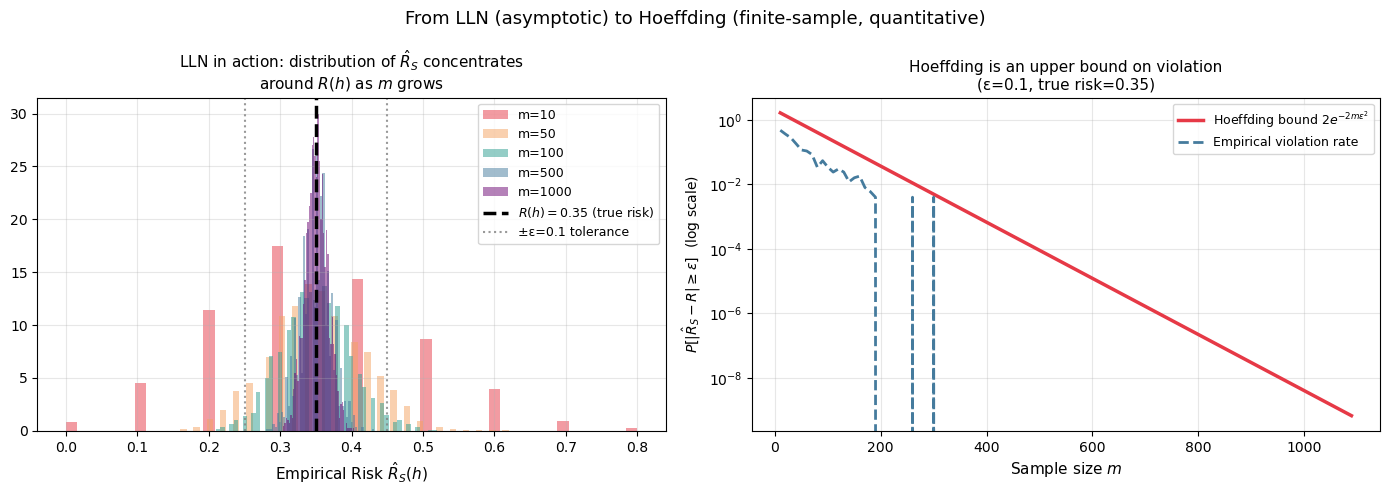

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

# True risk of a fixed hypothesis (unknown to learner)
R_true = 0.35
n_experiments = 2000
sample_sizes = [10, 50, 100, 500, 1000]
t = 0.10   # tolerance

empirical_means = {m: [] for m in sample_sizes}
for m in sample_sizes:
    for _ in range(n_experiments):
        losses = (rng.random(m) < R_true).astype(float)
        empirical_means[m].append(losses.mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: distribution of empirical risk for different m ---
ax = axes[0]
colors = ['#E63946','#F4A261','#2A9D8F','#457B9D','#6A0572']
for m, color in zip(sample_sizes, colors):
    ax.hist(empirical_means[m], bins=50, density=True, alpha=0.5,
            color=color, label=f'm={m}')
ax.axvline(R_true, color='black', lw=2.5, linestyle='--', label=f'$R(h)={R_true}$ (true risk)')
ax.axvline(R_true - t, color='gray', lw=1.5, linestyle=':', alpha=0.8)
ax.axvline(R_true + t, color='gray', lw=1.5, linestyle=':', alpha=0.8,
           label=f'±ε={t} tolerance')
ax.set_xlabel('Empirical Risk $\\hat{R}_S(h)$', fontsize=11)
ax.set_title('LLN in action: distribution of $\\hat{R}_S$ concentrates\naround $R(h)$ as $m$ grows', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# --- Right: Hoeffding bound vs empirical violation rate ---
ax2 = axes[1]
ms = np.arange(10, 1100, 10)
hoeffding_bound = 2 * np.exp(-2 * ms * t**2)

empirical_violation = []
for m in ms:
    violations = sum(
        abs((rng.random(m) < R_true).mean() - R_true) >= t
        for _ in range(500)
    ) / 500
    empirical_violation.append(violations)

ax2.semilogy(ms, hoeffding_bound, '#E63946', lw=2.5, label=f'Hoeffding bound $2e^{{-2m\\epsilon^2}}$')
ax2.semilogy(ms, empirical_violation, '#457B9D', lw=2, linestyle='--',
             label='Empirical violation rate')
ax2.set_xlabel('Sample size $m$', fontsize=11)
ax2.set_ylabel('$P[|\\hat{R}_S - R| \\geq \\epsilon]$  (log scale)', fontsize=10)
ax2.set_title(f'Hoeffding is an upper bound on violation\n(ε={t}, true risk={R_true})', fontsize=11)
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

plt.suptitle('From LLN (asymptotic) to Hoeffding (finite-sample, quantitative)', fontsize=13)
plt.tight_layout()
plt.show()

## 2.3 Proof — Agnostic PAC via Hoeffding Bound

**Goal:** Bound the probability that the ERM solution $h_S = \arg\min_{h \in \mathcal{H}} \hat{R}_S(h)$ has high true risk.

**Step 1 — Uniform convergence.**
We want $\hat{R}_S(h) \approx R(h)$ for **all** $h \in \mathcal{H}$ simultaneously. Apply Hoeffding to each $h$ and take a union bound over $\mathcal{H}$:

$$P\left[\exists\, h \in \mathcal{H} : |\hat{R}_S(h) - R(h)| > \frac{\epsilon}{2}\right] \leq 2|\mathcal{H}|\, e^{-2m(\epsilon/2)^2} = 2|\mathcal{H}|\, e^{-m\epsilon^2/2}$$

**Step 2 — Transfer the bound to ERM.**
On the event where uniform convergence holds (probability $\geq 1-\delta$), for $h_S = \arg\min \hat{R}_S$:

$$
R(h_S) \leq \hat{R}_S(h_S) + \frac{\epsilon}{2} \leq \hat{R}_S(h^*_{\mathcal H}) + \frac{\epsilon}{2} \leq R(h^*_{\mathcal H}) + \epsilon
$$

where $h^*_{\mathcal H} = \arg\min_{h \in \mathcal{H}} R(h)$ is the best hypothesis **in the class** (not to be confused with the Bayes classifier $h^*$ of `01_statistical_learning_theory`, which is the best over *all* measurable functions).

**Step 3 — Solve for $m$.**
Set $2|\mathcal{H}|\, e^{-m\epsilon^2/2} \leq \delta$:

$$
\boxed{m \geq \frac{2}{\epsilon^2}\left(\log|\mathcal{H}| + \log\frac{2}{\delta}\right)}
$$

---

## 2.4 Consistent vs Agnostic — A Critical Comparison

| | **Consistent (Realizable)** | **Agnostic (Unrealizable)** |
|---|---|---|
| Assumption | $c^* \in \mathcal{H}$, zero train error | None — $c^*$ may not be in $\mathcal{H}$ |
| Tool | Union bound only | Hoeffding + Union bound |
| Sample complexity | $m \geq \dfrac{1}{\epsilon}\log\dfrac{|\mathcal{H}|}{\delta}$ | $m \geq \dfrac{2}{\epsilon^2}\log\dfrac{2|\mathcal{H}|}{\delta}$ |
| Dependence on $\epsilon$ | $\mathcal{O}(1/\epsilon)$ | $\mathcal{O}(1/\epsilon^2)$ |
| Guarantee | $R(h_S) \leq \epsilon$ | $R(h_S) \leq \min_h R(h) + \epsilon$ |

### ⚠️ Key message for the student

The dependence on $\epsilon$ changes from $1/\epsilon$ to $1/\epsilon^2$ — this is not a minor detail. To achieve the same accuracy $\epsilon$ with the same confidence $\delta$:

- Consistent learner needs $m \propto 1/\epsilon$ samples
- Agnostic learner needs $m \propto 1/\epsilon^2$ samples — **quadratically more**

For example, to go from $\epsilon = 0.1$ to $\epsilon = 0.01$:
- Consistent: $10\times$ more samples
- Agnostic: $100\times$ more samples

This gap reflects the fundamental difficulty of learning without assumptions: in the agnostic setting we must control the worst-case fluctuation of the empirical risk uniformly over $\mathcal{H}$, and Hoeffding's bound introduces a quadratic cost in $\epsilon$.

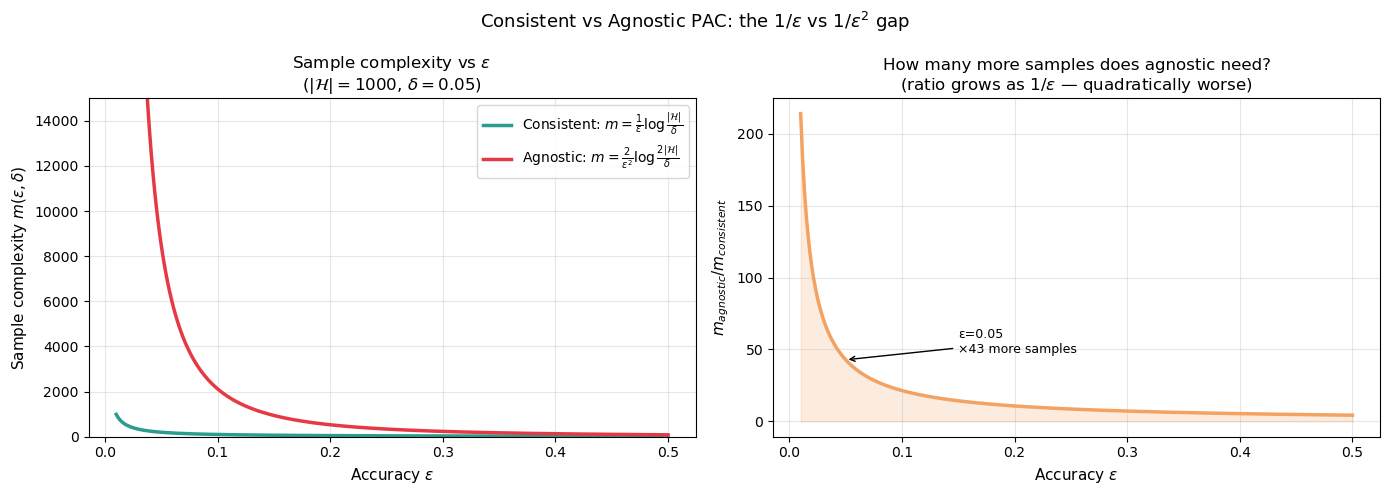

=== Numeric comparison: samples needed for same (ε, δ) ===
     ε |     Consistent |       Agnostic |    Ratio
--------------------------------------------------
  0.20 |             50 |            530 |    10.6x
  0.10 |            100 |          2,120 |    21.2x
  0.05 |            199 |          8,478 |    42.6x
  0.01 |            991 |        211,933 |   213.9x


In [4]:
import numpy as np
import matplotlib.pyplot as plt

H_size = 1000   # |H|
delta  = 0.05
epsilons = np.linspace(0.01, 0.5, 300)

m_consistent = (1 / epsilons) * np.log(H_size / delta)
m_agnostic   = (2 / epsilons**2) * np.log(2 * H_size / delta)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: sample complexity vs epsilon ---
ax = axes[0]
ax.plot(epsilons, m_consistent, '#2A9D8F', lw=2.5, label='Consistent: $m = \\frac{1}{\\epsilon}\\log\\frac{|\\mathcal{H}|}{\\delta}$')
ax.plot(epsilons, m_agnostic,   '#E63946', lw=2.5, label='Agnostic: $m = \\frac{2}{\\epsilon^2}\\log\\frac{2|\\mathcal{H}|}{\\delta}$')
ax.set_xlabel('Accuracy $\\epsilon$', fontsize=11)
ax.set_ylabel('Sample complexity $m(\\epsilon, \\delta)$', fontsize=11)
ax.set_ylim(0, 15000)
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
ax.set_title(f'Sample complexity vs $\\epsilon$\n($|\\mathcal{{H}}|={H_size}$, $\\delta={delta}$)', fontsize=12)

# --- Right: ratio agnostic/consistent ---
ax2 = axes[1]
ratio = m_agnostic / m_consistent
ax2.plot(epsilons, ratio, '#F4A261', lw=2.5)
ax2.fill_between(epsilons, ratio, alpha=0.2, color='#F4A261')
ax2.set_xlabel('Accuracy $\\epsilon$', fontsize=11)
ax2.set_ylabel('$m_{agnostic} / m_{consistent}$', fontsize=11)
ax2.set_title('How many more samples does agnostic need?\n(ratio grows as $1/\\epsilon$ — quadratically worse)', fontsize=12)
ax2.grid(True, alpha=0.3)

# Annotate a specific point
eps_ex = 0.05
r_ex = (2 / eps_ex**2 * np.log(2*H_size/delta)) / (1/eps_ex * np.log(H_size/delta))
ax2.annotate(f'ε=0.05\n×{r_ex:.0f} more samples',
             xy=(eps_ex, r_ex), xytext=(0.15, r_ex+5),
             arrowprops=dict(arrowstyle='->', color='black'),
             fontsize=9)

plt.suptitle('Consistent vs Agnostic PAC: the $1/\\epsilon$ vs $1/\\epsilon^2$ gap', fontsize=13)
plt.tight_layout()
plt.show()

print("=== Numeric comparison: samples needed for same (ε, δ) ===")
print(f"{'ε':>6} | {'Consistent':>14} | {'Agnostic':>14} | {'Ratio':>8}")
print("-" * 50)
for eps in [0.20, 0.10, 0.05, 0.01]:
    mc = int(np.ceil((1/eps) * np.log(H_size/delta)))
    ma = int(np.ceil((2/eps**2) * np.log(2*H_size/delta)))
    print(f"  {eps:.2f} | {mc:>14,} | {ma:>14,} | {ma/mc:>7.1f}x")

---
# 3. VC Dimension

## 3.1 Why We Need a New Complexity Measure

Everything so far assumed $\mathcal{H}$ is **finite**. The sample complexity bounds involved $\log|\mathcal{H}|$ — a perfectly well-defined quantity.

But most hypothesis classes we care about are **infinite**:
- All linear classifiers in $\mathbb{R}^d$: $|\mathcal{H}| = \infty$
- All neural networks with given architecture: $|\mathcal{H}| = \infty$
- All axis-aligned rectangles in $\mathbb{R}^2$: $|\mathcal{H}| = \infty$

When $|\mathcal{H}| \to \infty$, the bounds $\frac{1}{\epsilon}\log|\mathcal{H}|$ and $\frac{2}{\epsilon^2}\log|\mathcal{H}|$ become meaningless.

> **We need a notion of complexity that works for infinite hypothesis classes.**

The **VC dimension** (Vapnik & Chervonenkis, 1971) is that notion. It measures complexity not by counting hypotheses, but by measuring how many points the class can **shatter** — classify in all possible ways.

---

## 3.2 Shattering

**Definition (Shattering):** A hypothesis class $\mathcal{H}$ **shatters** a set $C = \{x_1, \dots, x_m\} \subseteq \mathcal{X}$ if for every possible labeling $y \in \{0,1\}^m$ there exists $h \in \mathcal{H}$ such that:

$$h(x_i) = y_i \quad \forall\, i = 1, \dots, m$$

In other words: $\mathcal{H}$ shatters $C$ if it can realize **all $2^m$ possible labelings** of $C$.

Intuitively: shattering means the hypothesis class is expressive enough to perfectly separate any configuration of $m$ points — it has total flexibility on that set.

---

## 3.3 VC Dimension — Definition

**Definition (VC Dimension):** The **VC dimension** of a hypothesis class $\mathcal{H}$ is:

$$
\boxed{d_{\mathrm{VC}}(\mathcal{H}) = \max\left\{ m \in \mathbb{N} \;:\; \exists\, C \subseteq \mathcal{X},\, |C| = m,\, \mathcal{H} \text{ shatters } C \right\}}
$$

The VC dimension is the size of the **largest set** that $\mathcal{H}$ can shatter.

- If $\mathcal{H}$ can shatter some set of size $d$ but no set of size $d+1$, then $d_{\mathrm{VC}}(\mathcal{H}) = d$
- If $\mathcal{H}$ can shatter sets of arbitrarily large size: $d_{\mathrm{VC}}(\mathcal{H}) = \infty$

---

## 3.4 The $d+1$ Result — Linear Classifiers in $\mathbb{R}^d$

The most important classical result:

**Theorem:** The VC dimension of the class of linear classifiers with a bias term — **affine halfspaces** $\{x \mapsto \operatorname{sign}(w^\top x + b) : w \in \mathbb{R}^d, b \in \mathbb{R}\}$ — in $\mathbb{R}^d$ is:
$$d_{\mathrm{VC}} = d + 1$$

For **homogeneous halfspaces** (no bias, $x \mapsto \operatorname{sign}(w^\top x)$, hyperplanes through the origin) the VC dimension is $d$ (SSBD Thm 9.2–9.3).

**Why $d+1$?**
- Any $d+1$ points in **general position** in $\mathbb{R}^d$ can be shattered by a hyperplane → $d_{\mathrm{VC}} \geq d+1$
- No set of $d+2$ points can be shattered (Radon's theorem: any $d+2$ points in $\mathbb{R}^d$ can be split into two groups whose convex hulls intersect, and that labeling is not linearly separable) → $d_{\mathrm{VC}} \leq d+1$

**Crucial implication — dimensionality and complexity:**

The VC dimension grows **linearly with the number of features** $d$. More dimensions = richer class = harder to learn. The sample complexity of the agnostic case becomes (SSBD Thm 6.8, see §3.5):

$$m = \Theta\!\left(\frac{d + \log(1/\delta)}{\epsilon^2}\right)$$

where $\Theta$ hides absolute constants that the theorem does not specify. So the **sample complexity grows linearly with the number of features** (for linear classifiers). This linear growth is mild compared to the exponential growth that the term *curse of dimensionality* usually refers to (see `04_pca`, §1).

Below, the first figure checks the $d = 2$ case directly: it tests every labeling of 3 and of 4 points for linear separability with a linear-programming feasibility problem — find $(w, b)$ with $y_i(w^\top x_i + b) \geq 1$ for all $i$, labels $y_i \in \{-1,+1\}$ — the same test used in `08_svm_and_kernel_methods`, §12.

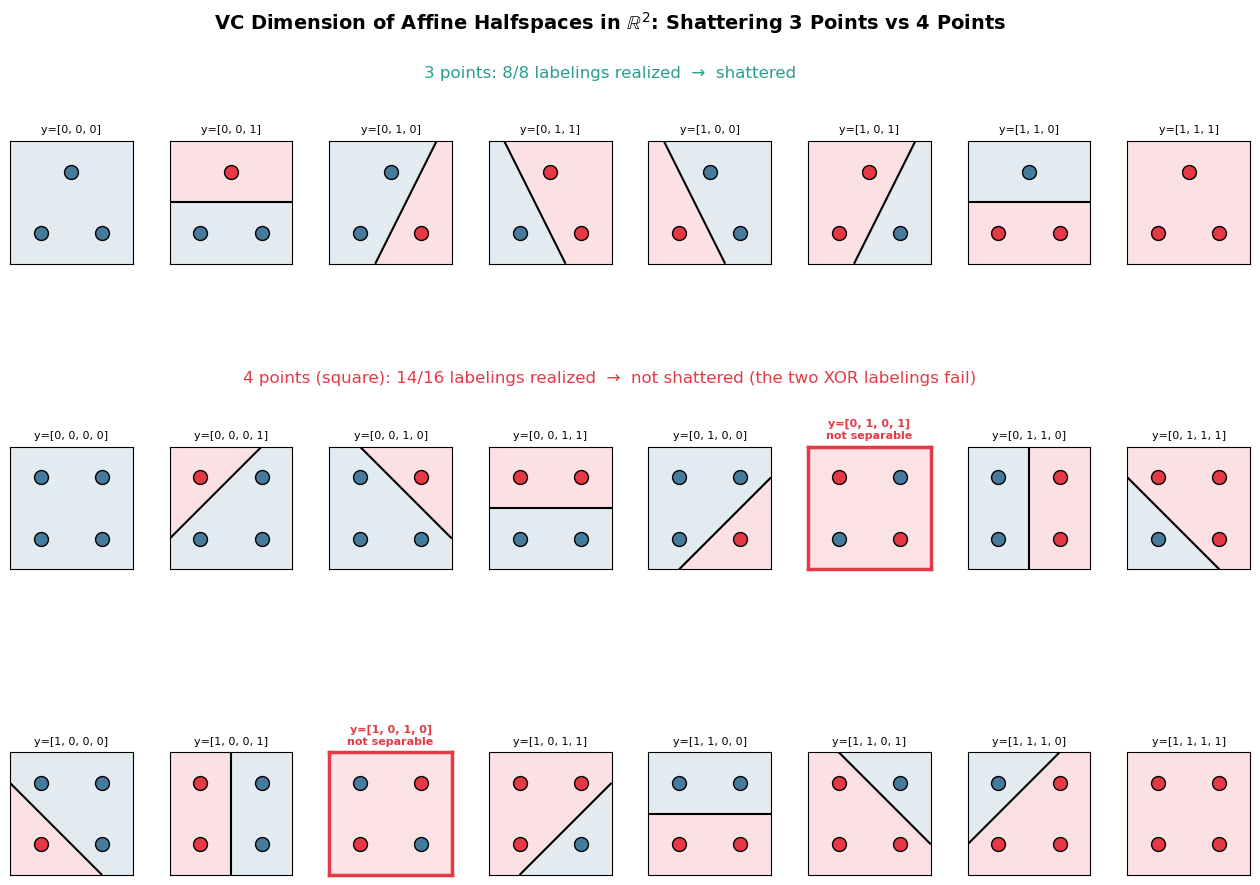

3 points: 8/8 labelings realized
4 points: 14/16 labelings realized
Non-separable labelings of the square: [[0, 1, 0, 1], [1, 0, 1, 0]]


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.optimize import linprog

def separate(X, y01):
    # LP: find (w, b) with y_i (w^T x_i + b) >= 1, y in {-1,+1}, minimizing ||w||_1.
    # Feasible <=> the labeling is linearly separable. Returns (separable, w, b).
    y = 2 * np.asarray(y01) - 1
    N, d = X.shape
    # variables: w+ (d), w- (d), b (1);  w = w+ - w-
    A_ub = -y[:, None] * np.hstack([X, -X, np.ones((N, 1))])
    c = np.concatenate([np.ones(2 * d), [0.0]])
    bounds = [(0, None)] * (2 * d) + [(None, None)]
    res = linprog(c, A_ub=A_ub, b_ub=-np.ones(N), bounds=bounds, method='highs')
    if res.status != 0:
        return False, None, None
    return True, res.x[:d] - res.x[d:2 * d], res.x[-1]

# --- Data ---
pts3 = np.array([[0.2, 0.2], [0.8, 0.2], [0.5, 0.8]])
pts4 = np.array([[0.2, 0.2], [0.8, 0.2], [0.8, 0.8], [0.2, 0.8]])   # counter-clockwise from bottom-left

labelings_3 = list(product([0, 1], repeat=3))   # 2^3 = 8
labelings_4 = list(product([0, 1], repeat=4))   # 2^4 = 16

colors_map = {0: '#457B9D', 1: '#E63946'}
x_grid = np.linspace(-0.1, 1.1, 200)
xx, yy = np.meshgrid(x_grid, x_grid)
grid_pts = np.c_[xx.ravel(), yy.ravel()]

def draw(ax, pts, labeling):
    ok, w, b = separate(pts, labeling)
    if ok:
        Z = (grid_pts @ w + b > 0).astype(int).reshape(xx.shape)
        ax.contourf(xx, yy, Z, alpha=0.15, colors=['#457B9D', '#E63946'], levels=[-0.5, 0.5, 1.5])
        if np.linalg.norm(w) > 1e-9:
            ax.contour(xx, yy, grid_pts.dot(w).reshape(xx.shape) + b, levels=[0], colors='k', linewidths=1.5)
        ax.set_title(f'y={list(labeling)}', fontsize=8)
    else:
        ax.set_facecolor('#fbe3e5')
        for spine in ax.spines.values():
            spine.set_edgecolor('#E63946'); spine.set_linewidth(2.5)
        ax.set_title(f'y={list(labeling)}\nnot separable', fontsize=8, color='#E63946', fontweight='bold')
    for pt, lbl in zip(pts, labeling):
        ax.scatter(*pt, s=100, color=colors_map[lbl], edgecolors='black', zorder=5)
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.1, 1.1)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')
    return ok

fig = plt.figure(figsize=(16, 10.5))
gs = fig.add_gridspec(3, 8, hspace=0.55, wspace=0.3)

# --- Row 1: all 8 labelings of 3 points ---
k3 = sum(draw(fig.add_subplot(gs[0, i]), pts3, lab) for i, lab in enumerate(labelings_3))
# --- Rows 2-3: all 16 labelings of 4 points (square) ---
k4 = sum(draw(fig.add_subplot(gs[1 + i // 8, i % 8]), pts4, lab) for i, lab in enumerate(labelings_4))

fig.text(0.5, 0.905, f'3 points: {k3}/{2**3} labelings realized  →  shattered', ha='center', fontsize=12, color='#2A9D8F')
fig.text(0.5, 0.615, f'4 points (square): {k4}/{2**4} labelings realized  →  not shattered (the two XOR labelings fail)',
         ha='center', fontsize=12, color='#E63946')
plt.suptitle('VC Dimension of Affine Halfspaces in $\\mathbb{R}^2$: Shattering 3 Points vs 4 Points', fontsize=14, y=0.97, fontweight='bold')
plt.show()

print(f"3 points: {k3}/8 labelings realized")
print(f"4 points: {k4}/16 labelings realized")
print("Non-separable labelings of the square:", [list(l) for l in labelings_4 if not separate(pts4, l)[0]])

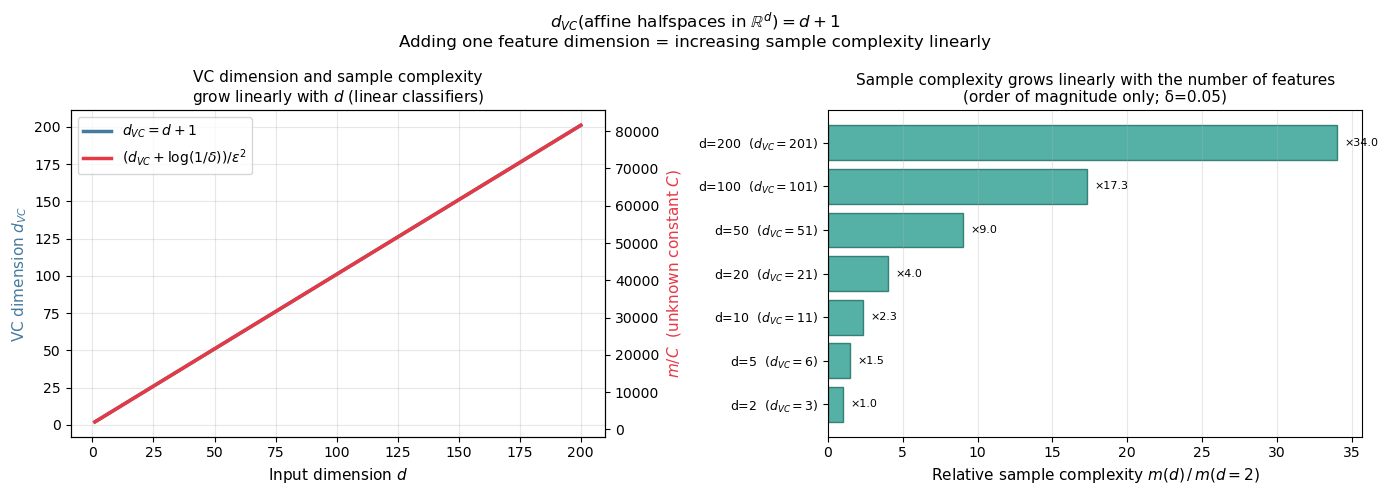

=== Sample-complexity scaling vs dimension (δ=0.05) — only ratios are meaningful ===
    d |   d_VC |  m(d) / m(d=2)
--------------------------------
    2 |      3 |            1.0
    5 |      6 |            1.5
   10 |     11 |            2.3
   50 |     51 |            9.0
  100 |    101 |           17.3
  200 |    201 |           34.0


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# VC dimension of affine halfspaces in R^d = d+1
# Agnostic sample complexity (SSBD Thm 6.8):
#   C1 (d_VC + log(1/delta)) / eps^2  <=  m  <=  C2 (d_VC + log(1/delta)) / eps^2
# with absolute constants C1, C2 that the theorem does not specify.
# We therefore plot only the scaling, m / C = (d_VC + log(1/delta)) / eps^2.

dimensions = np.arange(1, 201)   # d from 1 to 200
vc_dims    = dimensions + 1      # d_VC = d + 1

epsilon = 0.05
delta   = 0.05

m_scale = (vc_dims + np.log(1/delta)) / epsilon**2     # m up to an unknown constant

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: VC dim and sample-complexity scaling vs dimensionality
ax = axes[0]
ax2_twin = ax.twinx()
l1, = ax.plot(dimensions, vc_dims, '#457B9D', lw=2.5, label='$d_{VC} = d+1$')
l2, = ax2_twin.plot(dimensions, m_scale, '#E63946', lw=2.5, label='$(d_{VC} + \\log(1/\\delta))/\\epsilon^2$')
ax.set_xlabel('Input dimension $d$', fontsize=11)
ax.set_ylabel('VC dimension $d_{VC}$', fontsize=11, color='#457B9D')
ax2_twin.set_ylabel('$m / C$  (unknown constant $C$)', fontsize=11, color='#E63946')
ax.set_title('VC dimension and sample complexity\ngrow linearly with $d$ (linear classifiers)', fontsize=11)
lines = [l1, l2]
ax.legend(lines, [l.get_label() for l in lines], fontsize=10)
ax.grid(True, alpha=0.3)

# Right: relative sample complexity m(d) / m(d=2) -- independent of the unknown constant
ax3 = axes[1]
ds_select = [2, 5, 10, 20, 50, 100, 200]
ref = (2 + 1 + np.log(1/delta))
ratios = [(d + 1 + np.log(1/delta)) / ref for d in ds_select]
bars = ax3.barh(range(len(ds_select)), ratios, color='#2A9D8F', alpha=0.8, edgecolor='#1a6b5e')
ax3.set_yticks(range(len(ds_select)))
ax3.set_yticklabels([f'd={d}  ($d_{{VC}}={d+1}$)' for d in ds_select], fontsize=9)
ax3.set_xlabel('Relative sample complexity $m(d)\\,/\\,m(d=2)$', fontsize=11)
ax3.set_title(f'Sample complexity grows linearly with the number of features\n(order of magnitude only; δ={delta})', fontsize=11)
for bar, r in zip(bars, ratios):
    ax3.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'×{r:.1f}', va='center', fontsize=8)
ax3.grid(True, alpha=0.3, axis='x')

plt.suptitle(
    '$d_{VC}(\\text{affine halfspaces in } \\mathbb{R}^d) = d+1$\n'
    'Adding one feature dimension = increasing sample complexity linearly',
    fontsize=12
)
plt.tight_layout()
plt.show()

print("=== Sample-complexity scaling vs dimension (δ=0.05) — only ratios are meaningful ===")
print(f"{'d':>5} | {'d_VC':>6} | {'m(d) / m(d=2)':>14}")
print("-" * 32)
for d in [2, 5, 10, 50, 100, 200]:
    print(f"  {d:>3} | {d+1:>6} | {(d + 1 + np.log(1/delta)) / ref:>14.1f}")

## 3.5 From VC Dimension to a Bound

Why does a finite VC dimension replace $\log|\mathcal H|$? The answer goes through the number of *distinct behaviours* of $\mathcal H$ on a finite sample.

**Growth function.** For $C \subseteq \mathcal X$ let $\mathcal H_C = \{(h(x_1), \dots, h(x_m)) : h \in \mathcal H\}$ be the set of labelings of $C$ that $\mathcal H$ realizes. The growth function is
$$\tau_{\mathcal H}(m) = \max_{C \subseteq \mathcal X,\; |C| = m} |\mathcal H_C| \;\leq\; 2^m$$
and $\mathcal H$ shatters some set of size $m$ iff $\tau_{\mathcal H}(m) = 2^m$.

**Sauer–Shelah lemma** (SSBD Lemma 6.10). If $d_{\mathrm{VC}}(\mathcal H) = d < \infty$, then for all $m$
$$\tau_{\mathcal H}(m) \leq \sum_{i=0}^{d} \binom{m}{i}, \qquad\text{and in particular}\qquad \tau_{\mathcal H}(m) \leq \left(\frac{em}{d}\right)^d \text{ for } m > d+1.$$
The growth function jumps from exponential ($2^m$, for $m \le d$) to polynomial in $m$. Plugging $\log \tau_{\mathcal H}(2m) = O(d \log m)$ in place of $\log|\mathcal H|$ in a symmetrization version of the union-bound argument of §1.4 and §2.3 gives uniform convergence for infinite classes.

**Fundamental Theorem of PAC learning** (SSBD Thm 6.7–6.8). For binary classification with the 0-1 loss, the following are equivalent: $\mathcal H$ has the uniform convergence property; $\mathcal H$ is agnostic PAC learnable; $\mathcal H$ is PAC learnable; ERM is a successful (agnostic) PAC learner for $\mathcal H$; $d_{\mathrm{VC}}(\mathcal H) < \infty$. Quantitatively, if $d_{\mathrm{VC}}(\mathcal H) = d < \infty$ there are absolute constants $C_1, C_2$ such that
$$
\text{realizable:}\quad C_1 \frac{d + \log(1/\delta)}{\epsilon} \;\le\; m(\epsilon, \delta) \;\le\; C_2 \frac{d \log(1/\epsilon) + \log(1/\delta)}{\epsilon},
\qquad
\text{agnostic:}\quad C_1 \frac{d + \log(1/\delta)}{\epsilon^2} \;\le\; m(\epsilon, \delta) \;\le\; C_2 \frac{d + \log(1/\delta)}{\epsilon^2}.
$$
These are the infinite-class analogues of the $\frac1\epsilon \log\frac{|\mathcal H|}{\delta}$ and $\frac{2}{\epsilon^2}\log\frac{2|\mathcal H|}{\delta}$ bounds of §1.4 and §2.3, with $\log|\mathcal H|$ replaced by $d$.

**Link back to §1.** Axis-aligned rectangles in $\mathbb R^2$ have $d_{\mathrm{VC}} = 4$: four points in a "diamond" (one leftmost, one rightmost, one top, one bottom) can be shattered, but among any five points, the rectangle spanned by the leftmost, rightmost, highest and lowest of them also contains the fifth, so labeling those four positive and the fifth negative is impossible. The theorem therefore guarantees $m = O\!\left(\frac{\log(1/\epsilon) + \log(1/\delta)}{\epsilon}\right)$ in the realizable case — consistent with the direct bound $\frac{4}{\epsilon}\ln\frac{4}{\delta}$ of §1.5.

---
## Summary

| Concept | Key result | Intuition |
|---|---|---|
| **PAC learnability** | P[R(h_S) ≤ ε] ≥ 1 - δ | Probably Approximately Correct (High probability, low error) |
| **Sample complexity** | m(ε, δ) = min samples for the (ε, δ) guarantee | Quantifies how much data is enough to learn |
| **Consistent learner** | m ≥ (1/ε) · ln(\|H\| / δ) | Zero empirical error case; uses Union Bound over finite H |
| **Rectangle learner** | Tightest fit h_S ⊆ c*, P[R(h_S) > ε] ≤ 4e^(−mε/4) | Bad event: some ε/4-strip receives no training point |
| **Agnostic learner** | m ≥ (2/ε²) · ln(2\|H\| / δ) | Real-world case; handles noise using Hoeffding Inequality |
| **LLN vs Hoeffding** | Asymptotic vs Finite-Sample | Hoeffding gives a strict speed bound, LLN only guarantees t → ∞ |
| **Consistent vs Agnostic** | 1/ε vs 1/ε² speed | Removing the "zero error" assumption costs quadratically more data |
| **Shattering** | H realizes all 2ᵐ labelings | Measures the maximum shattering capacity on a finite set |
| **VC dimension** | d_VC = max shattered size | Replaces \|H\| to measure complexity for **infinite** hypothesis classes |
| **Linear classifiers** | d_VC = d + 1 (affine), d (homogeneous) | In a d-dimensional space, affine halfspaces shatter at most d+1 points |
| **Sauer–Shelah** | τ_H(m) ≤ (em/d)^d for m > d+1 | Finite VC dimension ⇒ polynomial growth function ⇒ uniform convergence |
| **Fundamental Theorem** | finite d_VC ⇔ (agnostic) PAC learnable | m = Θ((d + log(1/δ))/ε²) in the agnostic case |
| **Sample complexity vs d** | m = Θ((d + log(1/δ)) / ε²) | Grows linearly with the number of features (constants unspecified) |

---

**Next →** `03_linear_algebra_and_geometry.ipynb`: the linear-algebra and geometry toolkit (inner products, norms, eigendecomposition, SVD, matrix calculus) used by notebooks 04–08.

